In [1]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

from IPython.display import HTML

In [2]:
pitch_classes = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B' ]
states = [f"{p} Maj" for p in pitch_classes] + [f"{p} Min" for p in pitch_classes]

In [3]:
def extract_chroma(file_path):
    # 1. Load the audio file (librosa defaults to 22050 Hz and downmixes to mono
    print(f"Loading {file_path}...")
    y, sr = librosa.load(file_path)

    # 2. Extract the Chromagram using Constant-Q Transform
    chroma = librosa.feature.chroma_cqt(y=y, sr=sr)

    # 3. Average the energy aceoss the duration of the audio snippet
    # just for dev - This collapses the time domain to give us a single 12-bin array for the chord
    chroma_mean = np.mean(chroma, axis=1)

    # 4. Define the 12 Western pitch classes
    # pitch_classes = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B' ]

    # 5. Print the energy peaking for each pitch class
    print(f"\n--- Pitch Class Energy ---")
    for pitch, energy in zip(pitch_classes, chroma_mean):
        # Using a simple bar visualization in terminal for debugging
        bar = '=' * int(energy * 20)
        print(f"{pitch:>2}: {energy:.4f} | {bar}")

    # 6. PLot the chromagram over time to visualize the chord's sustained energy
    plt.figure(figsize=(10, 4))
    librosa.display.specshow(chroma, y_axis='chroma', x_axis='time')
    plt.colorbar(label='Energy')
    plt.title('Chromagram (Constant-Q Transform)')
    plt.tight_layout()
    plt.show()

    return chroma_mean

Loading ../data/raw/piano_chord.wav...

--- Pitch Class Energy ---
 C: 0.9721 | ===================
C#: 0.0704 | =
 D: 0.0947 | =
D#: 0.0636 | =
 E: 0.8142 | ================
 F: 0.0507 | =
F#: 0.0878 | =
 G: 0.6912 | =============
G#: 0.0517 | =
 A: 0.0273 | 
A#: 0.0393 | 
 B: 0.5850 | ===========


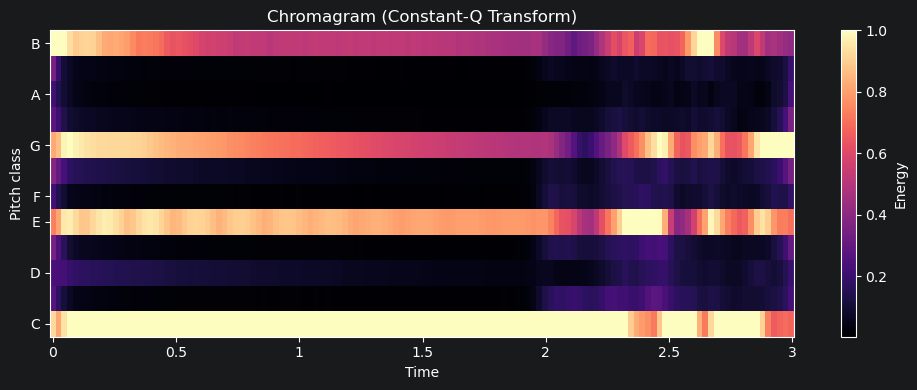

In [4]:
c_major_7_array = extract_chroma("../data/raw/piano_chord.wav")

In [6]:
# == Transition matrix for HMM

def build_transition_matrix():
    pitch_classes = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B' ]

    # Define the 24 states (0-11 are Major, 12-23 are Minor)
    states = [f"{p} Maj" for p in pitch_classes] + [f"{p} Min" for p in pitch_classes]
    num_states = len(states)

    # Initialize matrix with a tiny base probability (Laplace smoothing)
    # This prevents the HMM from throwing an error if an unexpected chbord happens
    trans_mat = np.full((num_states, num_states), .005)

    for i in range(12): # Loop through pitch roots
        # --- Major Chord Rules ---
        maj_idx = i

        # `1. Stay on same chord (Self-transition)
        trans_mat[maj_idx, maj_idx] = 0.6

        # 2. Perfect 5th (Dominant) & Perfect 4th (Subdominant)
        fifth_idx = (i + 7) % 12
        fourth_idx = (i + 5) % 12
        trans_mat[maj_idx, fifth_idx] = 0.1
        trans_mat[maj_idx, fourth_idx] = 0.05

        # 3. Relative Minor (Down 3 semitones) & Parallel Minor
        rel_min_idx = ((i - 3) % 12) + 12
        par_min_idx = i + 12
        trans_mat[maj_idx, rel_min_idx] = 0.05
        trans_mat[maj_idx, par_min_idx] = 0.05

        # Normalize the row so probabilities equal exactly to 1
        trans_mat[maj_idx] = trans_mat[maj_idx] / np.sum(trans_mat[maj_idx])


        # --- Minor Chord Rules ---
        min_idx = i + 12

        # `1. Stay on same chord (Self-transition)
        trans_mat[min_idx, min_idx] = 0.6

        # 2. Perfect 5th (Dominant) & Perfect 4th (Subdominant)
        fifth_idx = (min_idx + 7) % 12
        fourth_idx = (min_idx + 5) % 12
        trans_mat[min_idx, fifth_idx] = 0.1
        trans_mat[min_idx, fourth_idx] = 0.05

        # 3. Relative Major (Up 3 semitones) & Parallel Major
        rel_maj_idx = (min_idx + 3) % 12
        par_maj_idx = i - 12
        trans_mat[min_idx, rel_maj_idx] = 0.05
        trans_mat[min_idx, par_maj_idx] = 0.05

        # Normalize the row so probabilities equal exactly to 1
        trans_mat[min_idx] = trans_mat[min_idx] / np.sum(trans_mat[min_idx])

    return states, trans_mat



In [8]:
states, transition_matrix = build_transition_matrix()

In [12]:
df = pd.DataFrame(transition_matrix, index=states, columns=states)

print("Transition Probabilities from C Major:")
df.loc["C Maj"].sort_values(ascending=False).head(12)


Transition Probabilities from C Major:


C Maj     0.634921
G Maj     0.105820
F Maj     0.052910
A Min     0.052910
C Min     0.052910
E Maj     0.005291
D# Min    0.005291
A# Min    0.005291
D Maj     0.005291
G# Min    0.005291
G Min     0.005291
F# Min    0.005291
Name: C Maj, dtype: float64

In [30]:
def build_emission_templates():
    pitch_classes = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B' ]
    states = [f"{p} Maj" for p in pitch_classes] + [f"{p} Min" for p in pitch_classes]

    # We have 24 states (chords) and 12 observation bins (chroma features)
    # Start with a low background noise level (e.g. 0.1) instead of 0.0
    # to prevent the AI from breaking if a non-chord tone is played
    templates = np.full((24, 12), 0.1)

    for i in range(12):
        root = i
        perf_5th = (i+7) % 12

        # --- MAJOR CHORD TEMPLATE ---
        maj_3rd = ( i + 4 ) % 12

        templates[i, root] = 1.0
        templates[i, maj_3rd] = 1.0
        templates[i, perf_5th] = 1.0

        # Normazalize so the template sum to 1.0
        templates[i] = templates[i] / np.sum(templates[i])

        # --- MINOR CHORD TEMPLATE ---
        min_idx = i + 12
        min_3rd = ( i + 3 ) % 12

        templates[min_idx, root] = 1.0
        templates[min_idx, min_3rd] = 1.0
        templates[min_idx, perf_5th] = 1.0

        # Normazalize so the template sum to 1.0
        templates[min_idx] = templates[min_idx] / np.sum(templates[min_idx])

    return states, templates

In [31]:
states, emission_means = build_emission_templates()

In [36]:
df_emissions = pd.DataFrame(emission_means, index=states, columns=pitch_classes)

print(f"Ideal Chromagram Template for C Major")
print(df_emissions.loc["C Maj"].round(3))

print()
print(f"Ideal Chromagram Template for C Minor")
print(df_emissions.loc["C Min"].round(3))

Ideal Chromagram Template for C Major
C     0.256
C#    0.026
D     0.026
D#    0.026
E     0.256
F     0.026
F#    0.026
G     0.256
G#    0.026
A     0.026
A#    0.026
B     0.026
Name: C Maj, dtype: float64

Ideal Chromagram Template for C Minor
C     0.256
C#    0.026
D     0.026
D#    0.256
E     0.026
F     0.026
F#    0.026
G     0.256
G#    0.026
A     0.026
A#    0.026
B     0.026
Name: C Min, dtype: float64
